In [2]:
!pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn

In [3]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Load the UCI Heart Disease dataset

heart_disease = fetch_ucirepo(id=45)

# Separate features and target

X = heart_disease.data.features
y = heart_disease.data.targets

# Convert target into binary classification
# 0 = No heart disease
# 1 = Heart disease present (original values 1–4)

y = (y.iloc[:, 0] > 0).astype(int)

# Combine into one DataFrame

df = X.copy()
df["target"] = y

# Display dataset information

print("Dataset successfully loaded!")
print("-" * 40)

print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nTarget distribution:")
print(df["target"].value_counts())

Dataset successfully loaded!
----------------------------------------
Dataset shape: (303, 14)

First five records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


In [4]:
# Check missing values

print("MISSING VALUES")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate records

print("\nDUPLICATE RECORDS:", df.duplicated().sum())

# Statistical summary

print("\nSTATISTICAL SUMMARY")
display(df.describe().round(2))

MISSING VALUES
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Total missing values: 6

DUPLICATE RECORDS: 0

STATISTICAL SUMMARY


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,299.00,301.00,303.00
mean,54.44,0.68,3.16,131.69,246.69,0.15,0.99,149.61,0.33,1.04,1.60,0.67,4.73,0.46
std,9.04,0.47,0.96,17.60,51.78,0.36,0.99,22.88,0.47,1.16,0.62,0.94,1.94,0.50
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.50,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,241.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,275.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,1.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,1.00


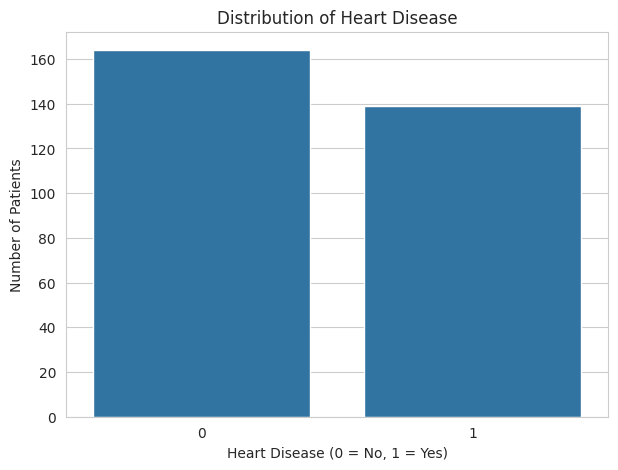

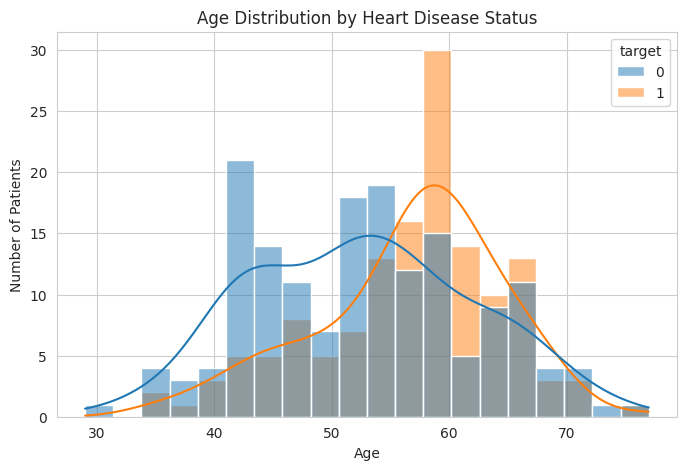

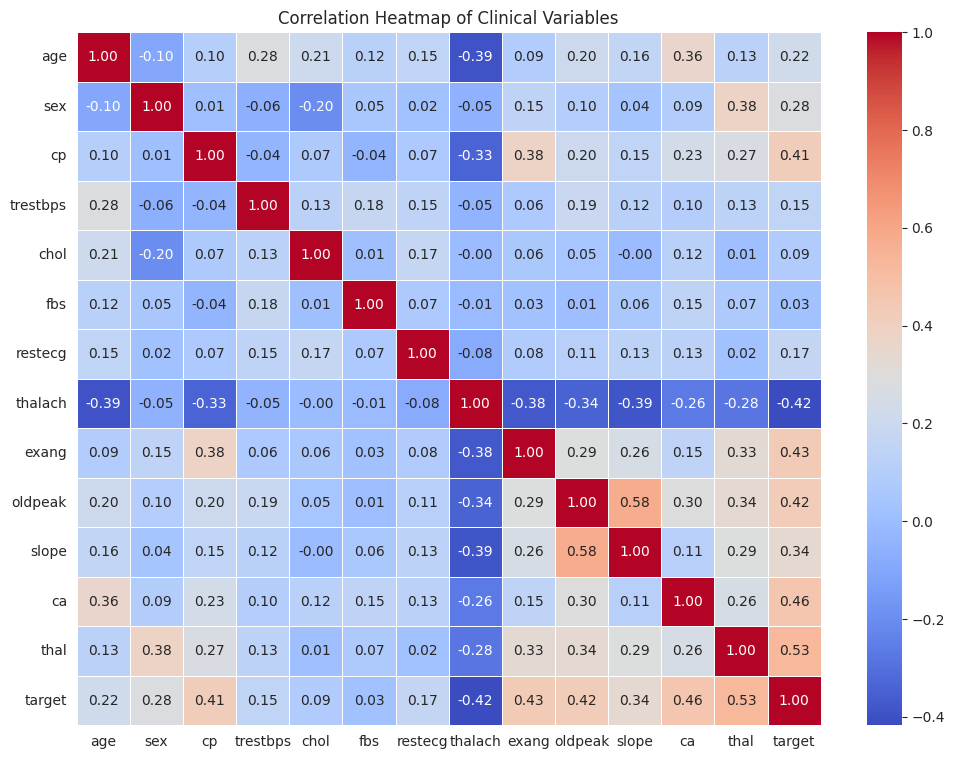

In [5]:
# Set visualisation style

sns.set_style("whitegrid")

# 1. Distribution of heart disease

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="target")

plt.title("Distribution of Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()


# 2. Age distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", hue="target",
             bins=20, kde=True, multiple="layer")

plt.title("Age Distribution by Heart Disease Status")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()


# 3. Correlation heatmap

plt.figure(figsize=(12, 9))

sns.heatmap(df.corr(), annot=True, fmt=".2f",
            cmap="coolwarm", linewidths=0.5)

plt.title("Correlation Heatmap of Clinical Variables")

plt.show()

In [6]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

# Identify categorical and numerical features

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

numerical_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

# Separate predictors and target

X = df.drop(columns=["target"])
y = df["target"]

# Split data before preprocessing

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Numerical preprocessing

numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing

preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

# Define models

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    )
}

# Train and evaluate models

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    print(f"\n{'='*50}")
    print(name)
    print("="*50)

    print("\nClassification Report:")
    print(classification_report(y_test, predictions))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

# Display model comparison

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(results_df.round(4))



Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

Confusion Matrix:
[[28  5]
 [ 2 26]]

Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

Confusion Matrix:
[[28  5]
 [ 2 26]]

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8852,0.8387,0.9286,0.8814,0.9665
1,Random Forest,0.8852,0.8387,0.9286,0.8814,0.9405


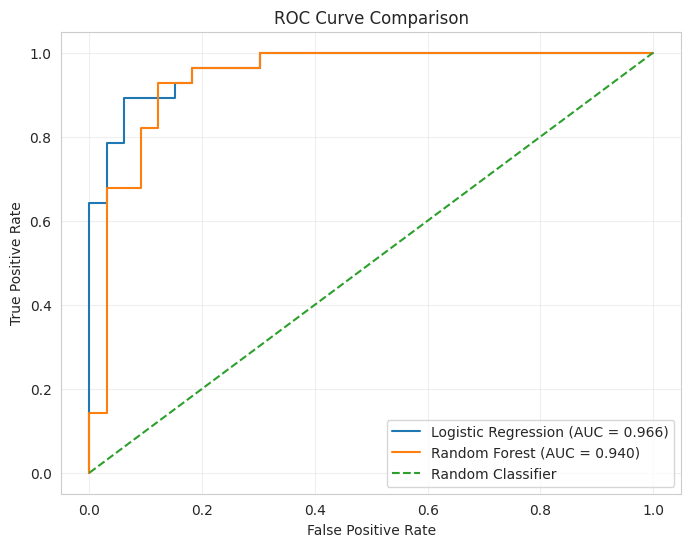


Logistic Regression - Feature Importance


,Feature,Importance,Std
11,ca,0.0674,0.0178
2,cp,0.0451,0.0134
9,oldpeak,0.0146,0.0040
10,slope,0.0109,0.0083
12,thal,0.0074,0.0089
3,trestbps,0.0071,0.0079
1,sex,0.0071,0.0073
8,exang,0.0060,0.0053
7,thalach,0.0051,0.0064
5,fbs,0.0030,0.0014



Random Forest - Feature Importance


,Feature,Importance,Std
11,ca,0.0458,0.0173
2,cp,0.0349,0.0134
8,exang,0.0124,0.0049
12,thal,0.0123,0.0117
9,oldpeak,0.0075,0.0086
7,thalach,0.0050,0.0056
0,age,0.0025,0.0065
10,slope,0.0020,0.0124
1,sex,-0.0026,0.0088
5,fbs,-0.0027,0.0031


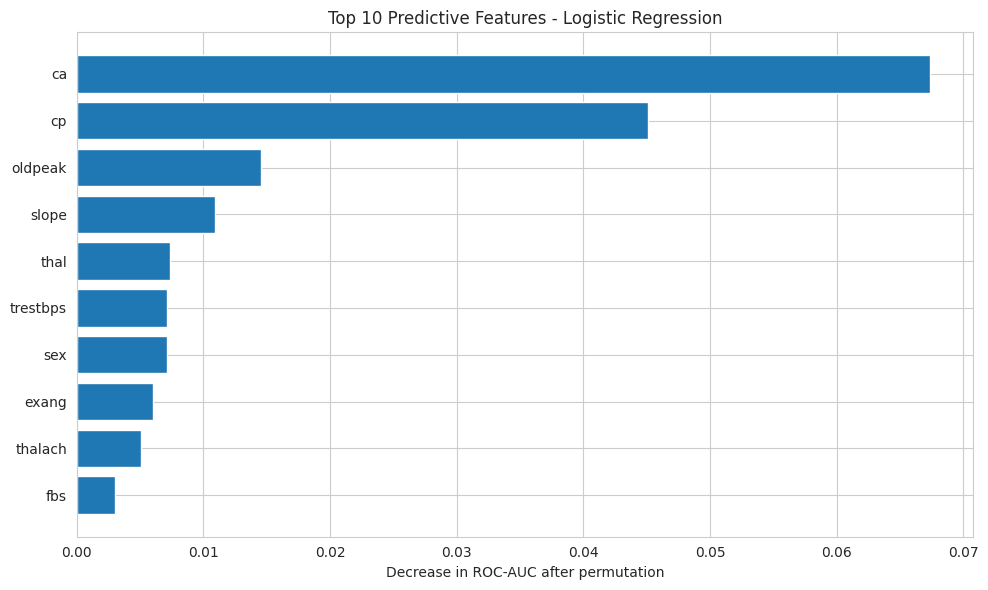


5-FOLD CROSS-VALIDATION RESULTS


,Model,Mean Accuracy,Mean F1,Mean ROC-AUC,ROC-AUC Std
0,Logistic Regression,0.8547,0.8332,0.9188,0.0207
1,Random Forest,0.8417,0.8214,0.9156,0.0208


In [7]:

from sklearn.metrics import roc_curve, auc
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate, StratifiedKFold

# Rebuild and retain fitted models

fitted_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline


# 1. Plot ROC curves

plt.figure(figsize=(8, 6))

for name, pipeline in fitted_models.items():

    probabilities = pipeline.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 2. Calculate permutation feature importance

importance_results = {}

for name, pipeline in fitted_models.items():

    importance = permutation_importance(
        pipeline,
        X_test,
        y_test,
        scoring="roc_auc",
        n_repeats=20,
        random_state=42
    )

    importance_df = pd.DataFrame({
        "Feature": X_test.columns,
        "Importance": importance.importances_mean,
        "Std": importance.importances_std
    }).sort_values(by="Importance", ascending=False)

    importance_results[name] = importance_df

    print(f"\n{name} - Feature Importance")
    display(importance_df.round(4))


# 3. Visualise Logistic Regression feature importance

plt.figure(figsize=(10, 6))

top_features = importance_results[
    "Logistic Regression"
].head(10).sort_values("Importance")

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Decrease in ROC-AUC after permutation")
plt.title("Top 10 Predictive Features - Logistic Regression")
plt.tight_layout()
plt.show()


# 4. Cross-validation for more reliable evaluation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=["accuracy", "f1", "roc_auc"],
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean F1": scores["test_f1"].mean(),
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    })

cv_df = pd.DataFrame(cv_results)

print("\n5-FOLD CROSS-VALIDATION RESULTS")
display(cv_df.round(4))


In [8]:

import joblib
import os

# Create project output folder

os.makedirs("heart_disease_project", exist_ok=True)

# Train final Logistic Regression pipeline on all available data
# Cross-validation results have already been calculated.

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

final_model.fit(X, y)

# Save trained model

joblib.dump(
    final_model,
    "heart_disease_project/heart_disease_model.pkl"
)

# Save evaluation results

results_df.to_csv(
    "heart_disease_project/model_comparison.csv",
    index=False
)

cv_df.to_csv(
    "heart_disease_project/cross_validation_results.csv",
    index=False
)

# Save feature importance

importance_results["Logistic Regression"].to_csv(
    "heart_disease_project/feature_importance.csv",
    index=False
)

print("PROJECT FILES SAVED SUCCESSFULLY!")

print("\nFiles created:")

for file in os.listdir("heart_disease_project"):
    print("-", file)

PROJECT FILES SAVED SUCCESSFULLY!

Files created:
- heart_disease_model.pkl
- model_comparison.csv
- cross_validation_results.csv
- feature_importance.csv


In [9]:
import shutil

shutil.make_archive(
    "heart_disease_project",
    "zip",
    "heart_disease_project"
)

print("Project archive created successfully!")

Project archive created successfully!
